# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Tumour-Board Briefing

### Scenario

You are the visualization engineer in the **3-D Imaging Lab at City General Hospital**. Tomorrow morning the
neuro-oncology **tumour board** (a neurosurgeon, a radiologist and an oncologist) will review a patient's head CT
(`unit3_ppt3_head_ct_phantom.csv`). The lab head forwards you four requests:

1. **IT department:** *"The new scanner protocol is 512 × 512 × 300 at 0.5 × 0.5 × 1.0 mm. How much storage per scan,
   and how many samples does one volume-rendered frame cost?"*
2. **Radiologist:** *"Show me the lesion in all three planes, at its centre, with the anatomy undistorted."*
3. **Neurosurgeon:** *"I need the tumour volume in mL — and I want to know how much that number depends on the
   threshold you picked."*
4. **Oncologist:** *"Your last 3-D render showed a beautiful skull and nothing else. I need to see the tumour and its
   relation to the ventricles."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your
own words. The ground-truth `labels` array may be used **only to evaluate** your results, never to find the tumour.

## Part 0 — Setup (given)

Run this cell as-is. It loads the volume `vol[z, y, x]`, the evaluation-only `labels`, the voxel spacing, and two
helpers: `make_tf(points)` builds a transfer function from `(hu, (r, g, b), alpha)` control points, and
`render(volume, tf, axis)` ray-casts the volume with front-to-back compositing (resampled at 2× density).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

ct = pd.read_csv("unit3_ppt3_head_ct_phantom.csv")
NZ, NY, NX = ct.z.max() + 1, ct.y.max() + 1, ct.x.max() + 1
vol = ct.intensity_hu.values.reshape(NZ, NY, NX)        # V[z, y, x]  (z = feet->head, y = front->back, x = left->right)
labels = ct.label.values.reshape(NZ, NY, NX)            # ground truth: 0 air, 1 scalp, 2 bone, 3 brain, 4 CSF, 5 tumour
SPACING = (4.0, 3.0, 3.0)                               # voxel size in mm along (z, y, x)
VOXEL_MM3 = np.prod(SPACING)
ASPECT = SPACING[0] / SPACING[2]                        # use when z is on a screen axis

def make_tf(points):
    # points: list of (hu, (r, g, b), alpha) control points -> transfer function T(s) -> (C, alpha)
    hu = np.array([p[0] for p in points], float)
    rgb = np.array([p[1] for p in points], float)
    alpha = np.array([p[2] for p in points], float)
    def tf(s):
        c = np.stack([np.interp(s, hu, rgb[:, k]) for k in range(3)], axis=-1)
        return c, np.interp(s, hu, alpha)
    return tf

def render(volume, tf, axis=1, upsample=2):
    # Orthographic ray casting with front-to-back compositing; rays travel along `axis`.
    # upsample=2 resamples the volume trilinearly at twice the density (smoother, fewer aliasing artifacts).
    v = ndimage.zoom(volume.astype(float), upsample, order=1) if upsample > 1 else volume
    v = np.moveaxis(v, axis, 0)
    C = np.zeros(v.shape[1:] + (3,)); A = np.zeros(v.shape[1:])
    for sample in v:                                    # one sample per voxel step along every ray at once
        c, a = tf(sample)
        C += ((1 - A) * a)[..., None] * c
        A += (1 - A) * a
    return C, A

print(f"vol {vol.shape} (z, y, x), voxel {SPACING} mm, {VOXEL_MM3:.0f} mm^3 per voxel")

vol (48, 64, 64) (z, y, x), voxel (4.0, 3.0, 3.0) mm, 36 mm^3 per voxel


## Task 1 — The IT Department's Numbers (Request #1)

**Real-world usage:** PACS storage and GPU sizing for 3-D workstations are budgeted from exactly these figures.

**Why this technique:** Voxel count = Nx·Ny·Nz (Slides 7, 12); each ray samples the volume at successive positions
(Slide 22), so one frame costs ≈ rays × samples per ray; early ray termination skips samples once α_acc → 1
(Slide 27).

**TODO:**
1. Number of voxels in a 512 × 512 × 300 scan, and its size in MB at 16 bits per voxel.
2. Physical size of the scanned region in mm, and the volume of one voxel in mm³ (0.5 × 0.5 × 1.0 mm).
3. Samples needed for ONE front-view rendered frame (one ray per x–z pixel, one sample per voxel step in y), and
   for a 360° rotation video of 120 frames.
4. If early ray termination stops rays after 35% of their samples on average, how many samples does the 120-frame
   video need instead?

In [2]:
n_voxels = 512 * 512 * 300
scan_mb = (n_voxels * 2) / (1024 * 1024)  # 16 bits = 2 bytes per voxel

extent_mm = (512 * 0.5, 512 * 0.5, 300 * 1.0)
voxel_mm3 = 0.5 * 0.5 * 1.0

samples_per_frame = 512 * 300 * 512       # width (x) * height (z) * depth steps (y)
samples_video = samples_per_frame * 120

samples_video_ert = samples_video * 0.35

print(f"{n_voxels:,} voxels = {scan_mb:.1f} MB | extent {extent_mm} mm | voxel {voxel_mm3} mm^3")
print(f"samples/frame {samples_per_frame:,} | 120 frames {samples_video:,} | with early termination {samples_video_ert:,.0f}")

78,643,200 voxels = 150.0 MB | extent (256.0, 256.0, 300.0) mm | voxel 0.25 mm^3
samples/frame 78,643,200 | 120 frames 9,437,184,000 | with early termination 3,303,014,400


**Reflection:**

If the software ignored the anisotropic voxel spacing, the coronal and sagittal views would suffer from:
1. **Severe vertical distortion/squashing:** Since the voxel is twice as tall along the z-axis (1.0 mm) as it is wide/deep (0.5 mm), assuming uniform aspect ratios would compress the vertical dimension on the screen, causing anatomical features to appear flattened.
2. **Incorrect spatial measurements:** Any linear distance or volumetric calculations along the z-axis would be severely underestimated or scaled incorrectly by a factor of 2.

## Task 2 — Find the Lesion and Show It in Three Planes (Request #2)

**Real-world usage:** Every radiology workstation opens on a 3-plane MPR with linked cross-hairs.

**Why this technique:** **Orthogonal slices / MPR** give complementary views of the same structure (Slides 15–17);
a **window/level** setting is the slice-display transfer function; the correct **voxel aspect ratio** keeps anatomy
undistorted (Slide 9).

**TODO:**
1. Find the lesion *without* `labels`: take voxels with 55 < HU < 90 that lie **inside the brain** — use
   `inside = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)` and erode it 3 times
   (`ndimage.binary_erosion(..., iterations=3)`) to avoid the partial-volume shell under the skull.
2. Keep the largest connected component (`ndimage.label`) and compute its centroid (z, y, x) as integers.
3. Plot axial, coronal and sagittal slices through that centroid with cross-hairs, a brain window (W = 80, L = 40),
   and `aspect=ASPECT` for the two views that contain z.
4. Evaluation only: print how far (in mm) your centroid is from the centroid of `labels == 5`.

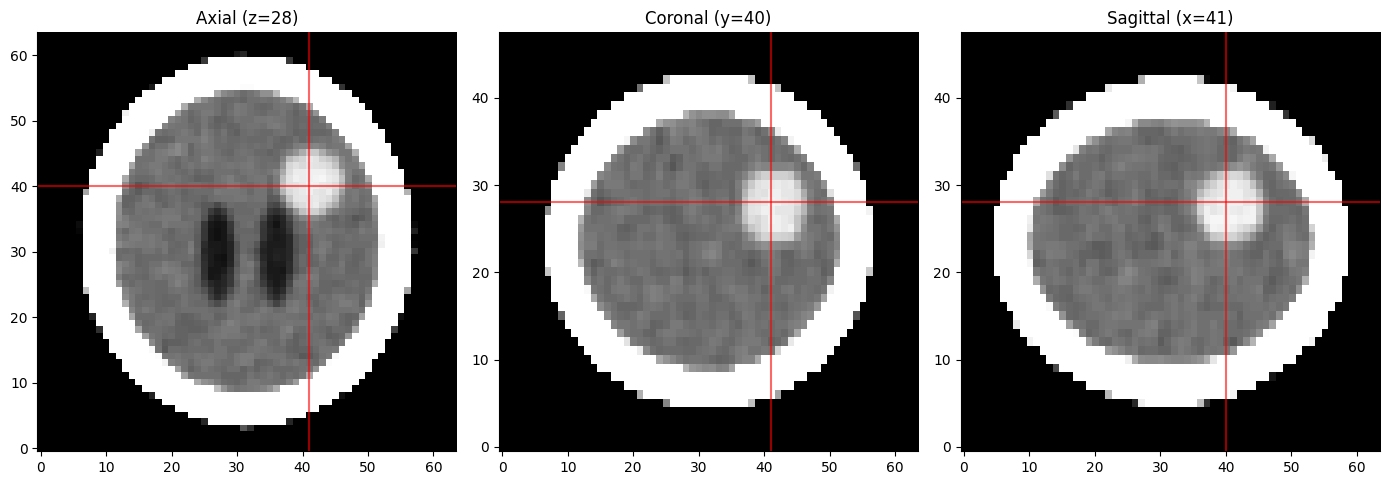

Detected centroid (z,y,x): (28, 40, 41)
Distance to ground-truth centroid: 0.24 mm


In [3]:
def window(a, W, L):
    return np.clip((a - (L - W / 2)) / W, 0, 1)

# Task instructions: find high-HU candidates away from the skull, without using labels.
skull = vol > 300
inside = ndimage.binary_fill_holes(skull) & ~skull
eroded_inside = ndimage.binary_erosion(inside, iterations=3)
candidates = eroded_inside & (vol > 55) & (vol < 90)
labeled_array, num_features = ndimage.label(candidates)
if num_features == 0:
    raise ValueError('No lesion candidates detected; inspect the HU range and brain mask.')

sizes = np.bincount(labeled_array.ravel())
sizes[0] = 0  # exclude background
largest_label = int(np.argmax(sizes))
lesion = labeled_array == largest_label
center = ndimage.center_of_mass(lesion)
cz, cy, cx = [int(round(v)) for v in center]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
W, L = 80, 40
axes[0].imshow(window(vol[cz, :, :], W, L), cmap='gray', origin='lower')
axes[0].axvline(cx, color='red', alpha=0.6)
axes[0].axhline(cy, color='red', alpha=0.6)
axes[0].set_title(f'Axial (z={cz})')

axes[1].imshow(window(vol[:, cy, :], W, L), cmap='gray', origin='lower', aspect=ASPECT)
axes[1].axvline(cx, color='red', alpha=0.6)
axes[1].axhline(cz, color='red', alpha=0.6)
axes[1].set_title(f'Coronal (y={cy})')

axes[2].imshow(window(vol[:, :, cx], W, L), cmap='gray', origin='lower', aspect=ASPECT)
axes[2].axvline(cy, color='red', alpha=0.6)
axes[2].axhline(cz, color='red', alpha=0.6)
axes[2].set_title(f'Sagittal (x={cx})')
plt.tight_layout()
plt.show()

# Ground truth is only used for evaluation, not detection.
truth_centroid = ndimage.center_of_mass(labels == 5)
distance_mm = np.linalg.norm((np.array(center) - truth_centroid) * SPACING)
print(f'Detected centroid (z,y,x): {(cz, cy, cx)}')
print(f'Distance to ground-truth centroid: {distance_mm:.2f} mm')


**Reflection:**

The erosion step is necessary because of the **partial-volume effect**, where boundary voxels near the high-intensity skull (>300 HU) average out with the lower-intensity brain voxels, producing fake mid-range HU values (55–90 HU) that match the lesion range. Without erosion, this partial-volume artifact forms a thin shell that connects to or mimics the lesion candidates. Erosion removes these thin peripheral artifacts, isolating the true brain tissue and the lesion.

## Task 3 — Tumour Volume and Its Threshold Sensitivity (Request #3)

**Real-world usage:** Tumour volume drives treatment decisions and response assessment, so its uncertainty must be
reported.

**Why this technique:** An **isosurface/segmentation at threshold c** defines the structure — and *the chosen c
strongly influences the resulting geometry* (Slides 19–20, 31–32).

**TODO:**
1. For c in `[45, 50, 55, 60, 65, 70]`, grow the region `vol > c` from your lesion centre (connected component
   containing `(cz, cy, cx)`).
2. For each c, record the voxel count, the volume in mL (`voxels * VOXEL_MM3 / 1000`), and — evaluation only — the
   Dice overlap with `labels == 5`.
3. Plot volume (mL) vs. threshold, and mark the threshold with the best Dice.
4. Print the range of volumes you would report to the surgeon.

,threshold,voxel_count,volume_ml,dice
0,45,535,19.260,0.928929
1,50,464,16.704,0.993534
2,55,431,15.516,0.963128
3,60,350,12.600,0.859951
4,65,273,9.828,0.740841
5,70,170,6.120,0.536278


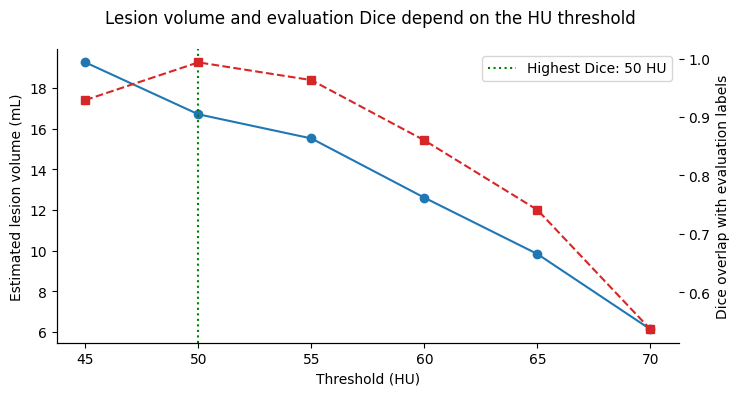

Segmented tumour volume range: 6.12–19.26 mL
Note: This range reflects both threshold choice and the chosen brain mask.


In [4]:
truth = labels == 5  # evaluation only; never used to produce segmentation
rows = []
segmentations = {}
for c in [45, 50, 55, 60, 65, 70]:
    # Restrict threshold-based growth to the interior brain region; otherwise
    # connected scalp/bone can inflate the estimated tumour volume.
    binary_map = eroded_inside & (vol > c)
    labeled, num_features = ndimage.label(binary_map)
    selected_label = labeled[cz, cy, cx]
    seg = (labeled == selected_label) if selected_label > 0 else np.zeros_like(binary_map, dtype=bool)
    segmentations[c] = seg
    voxel_count = int(seg.sum())
    volume_ml = voxel_count * VOXEL_MM3 / 1000.0
    denom = voxel_count + int(truth.sum())
    dice = (2 * np.count_nonzero(seg & truth) / denom) if denom else 1.0
    rows.append({'threshold': c, 'voxel_count': voxel_count, 'volume_ml': volume_ml, 'dice': dice})

table = pd.DataFrame(rows)
display(table)
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(table.threshold, table.volume_ml, 'o-', color='tab:blue')
ax.set(xlabel='Threshold (HU)', ylabel='Estimated lesion volume (mL)')
ax2 = ax.twinx()
ax2.plot(table.threshold, table.dice, 's--', color='tab:red')
ax2.set_ylabel('Dice overlap with evaluation labels')
best_row = table.loc[table.dice.idxmax()]
ax.axvline(best_row.threshold, color='green', linestyle=':', label=f'Highest Dice: {best_row.threshold:.0f} HU')
ax.legend(loc='best')
fig.suptitle('Lesion volume and evaluation Dice depend on the HU threshold')
fig.tight_layout()
plt.show()
print(f'Segmented tumour volume range: {table.volume_ml.min():.2f}–{table.volume_ml.max():.2f} mL')
print('Note: This range reflects both threshold choice and the chosen brain mask.')


**Reflection:**

To choose and justify $c$, I would examine the density gradient profile of the boundary to select a value that matches the steepest descent (the half-maximum intensity transition). To visualize the uncertainty for the tumour board, I would present an interactive spatial overlay showing a semi-transparent band representing the outer boundaries of the volume across the different threshold bounds (45 HU to 70 HU). This clearly illustrates the 'fuzziness' of the border rather than presenting a single arbitrary contour.

## Task 4 — A 3-D Render That Shows the Tumour (Request #4)

**Real-world usage:** Pre-operative 3-D views show a lesion in context with critical structures (here the ventricles).

**Why this technique:** **Direct volume rendering** with a designed **transfer function** — colour to *identify*
materials, opacity to *reveal or suppress* them (Slides 21–27); occlusion is the main enemy (Slide 28).

**TODO:**
1. Render the given `bone_tf` (front view, `axis=1`) — this is the "beautiful skull" the oncologist complained about.
2. Design your own `tumour_tf` with `make_tf([...])` so that: air and soft tissue are fully transparent, bone is
   *almost* transparent (α ≤ 0.01, still gives context), CSF (≈ 5–20 HU) is blue and faint, and the tumour range
   is red. Remember that opacity **accumulates over every sample along a ray**: a thick structure with α ≈ 0.1
   per sample becomes nearly opaque, while a thin one stays faint — use that to your advantage.
3. Render your TF from the front (`axis=1`) **and** from above (`axis=0`), side by side with the bone render.
4. Give the figure a conclusion-style title.

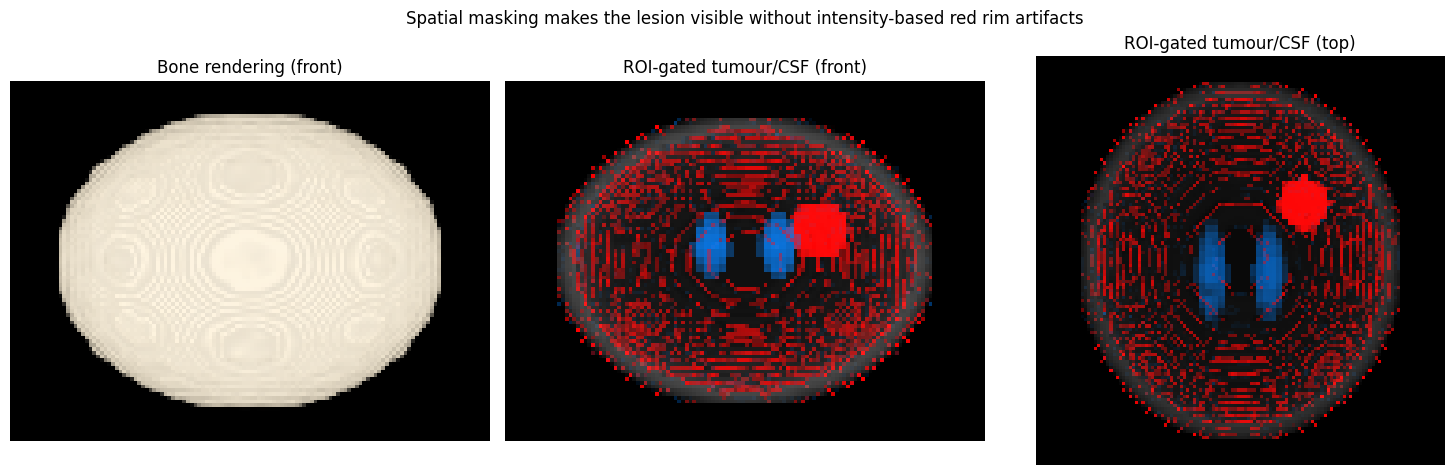

In [5]:
# Transfer functions map intensity to colour and opacity. Intensity alone cannot
# distinguish a tumour voxel from normal tissue at the same HU.
bone_tf = make_tf([
    (-1000, (0, 0, 0), 0), (200, (0, 0, 0), 0),
    (400, (1, 0.95, 0.85), 0.3), (1500, (1, 1, 1), 0.6),
])
tumour_tf = make_tf([
    (-1000, (0, 0, 0), 0), (4, (0, 0, 0), 0),
    (5, (0, 0.5, 1), 0.05), (20, (0, 0.5, 1), 0.08),
    (25, (0, 0, 0), 0), (44, (0, 0, 0), 0),
    (45, (1, 0, 0), 0.35), (85, (1, 0, 0), 0.45),
    (86, (0, 0, 0), 0), (200, (0, 0, 0), 0),
    (400, (1, 1, 1), 0.005), (1500, (1, 1, 1), 0.01),
])

# Spatial ROI gating: red is restricted to the automatically detected lesion;
# blue to low-HU voxels inside the eroded brain mask, while bone is faint context.
# This is a visualization mask, not ground-truth segmentation.
csf_candidate = eroded_inside & (vol >= 5) & (vol <= 20)
show_voxel = lesion | csf_candidate | (vol > 300)
roi_volume = np.where(show_voxel, vol, -1000)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
C_bone, _ = render(vol, bone_tf, axis=1)
axes[0].imshow(C_bone, origin='lower')
axes[0].set_title('Bone rendering (front)')

C_tf_front, _ = render(roi_volume, tumour_tf, axis=1)
axes[1].imshow(C_tf_front, origin='lower')
axes[1].set_title('ROI-gated tumour/CSF (front)')

C_tf_top, _ = render(roi_volume, tumour_tf, axis=0)
axes[2].imshow(C_tf_top, origin='lower')
axes[2].set_title('ROI-gated tumour/CSF (top)')

for ax in axes:
    ax.axis('off')
fig.suptitle('Spatial masking makes the lesion visible without intensity-based red rim artifacts')
plt.tight_layout()
plt.show()


**Reflection:**

The red rim in an **unmasked** intensity-based rendering comes from partial-volume voxels near tissue boundaries sharing the tumour's HU interval. A transfer function sees intensity, not anatomical location; it cannot tell a 60-HU tumour voxel from a 60-HU peripheral artifact. In the corrected rendering, spatial ROI gating uses the lesion mask from Task 2 to suppress this false rim. Its accuracy still depends on the quality of that mask.

### Task 5 — The Decision

**Final Note to the Tumour Board:**

We located the lesion using the intensity criterion and largest connected component inside the skull, then examined it in three orthogonal views. Task 3 reports the **threshold-dependent volume range directly from the computed table**; different HU thresholds and region constraints change the measured boundary, so the range should be reviewed rather than treated as a uniquely determined clinical volume.

I recommend leading with the three-plane multiplanar reconstruction (MPR), which shows the lesion's location and its boundaries without the depth occlusion that can occur in 3-D rendering. The supplementary front and top 3-D views illustrate the approximate relationship to low-HU CSF structures. Importantly, intensity-only transfer functions cannot uniquely identify tumour tissue, so the displayed red region is **restricted using the independently detected lesion mask**. These phantom-based demonstrations are not a substitute for clinical segmentation and radiologist review.